In [1]:
from tqdm.notebook import tqdm
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import pickle
pd.set_option('display.max_columns', None)
import time
import warnings
warnings.filterwarnings("ignore")
import os
import sys

In [3]:
import illume
from illume.data_utils import prepare_dataset
from illume.expl_utils import inverse_transform_rule_complete
from xgboost import XGBClassifier
from lightgbm import LGBMClassifier
from catboost import CatBoostClassifier

# Load Dataset

In [4]:
from sklearn.datasets import load_breast_cancer
df = load_breast_cancer(as_frame=True)['frame']
class_name = 'target'

In [5]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

df, feature_names, class_values, numeric_columns, rdf, real_feature_names, features_map = prepare_dataset(df, class_name, 'onehot')

X = df[feature_names].values.astype(np.float64)
y = df[class_name].values

X_train_orig, X_test_orig, y_train, y_test = train_test_split(X, y, test_size=0.2, stratify=y, random_state=42)
X_train_orig, X_val_orig, y_train, y_val = train_test_split(X_train_orig, y_train, test_size=0.2, stratify=y_train, random_state=42)

scaler = StandardScaler()

X_train, X_val, X_test = (X_train_orig.copy(), X_val_orig.copy(), X_test_orig.copy())

if len(numeric_columns)>0:
    numeric_idx = [idx for idx,f in enumerate(feature_names) if f in numeric_columns]
    X_train[:, numeric_idx] = scaler.fit_transform(X_train[:, numeric_idx])
    X_val[:, numeric_idx] = scaler.transform(X_val[:, numeric_idx])
    X_test[:, numeric_idx] = scaler.transform(X_test[:, numeric_idx])

In [7]:
idx_num_cat = [list(d.values()) for i,d in features_map.items()]

# Train Black-Box

In [ ]:
clf = LGBMClassifier(verbosity=-1, random_state=42)
# clf = CatBoostClassifier(random_state=42)
# clf = XGBClassifier(use_label_encoder=False, eval_metric='logloss', random_state=42)

clf.fit(X_train, y_train)

In [9]:
y_train_pred = clf.predict_proba(X_train)
y_val_pred = clf.predict_proba(X_val)

In [10]:
y_train_bb = clf.predict(X_train)
y_val_bb = clf.predict(X_val)
y_test_bb = clf.predict(X_test)

# Latent Encoding Training

### Run the code for training a dense meta-encoding.

In [11]:
latent = illume.ILLUME(latent_dim=8,
                        mlp_layers=3,
                        dropout=0.25,
                        nj_proj=1,
                        max_epochs=500,
                        early_stopping=30,
                        learning_rate=0.001,
                        batch_size=256,)

Important inputs:
- X=(X_train, X_val) : train/validation sets for validation accuracy / early stopping
- y=(y_train_pred, y_val_pred) : predicted black-box probabilities (optional)
- idx_num_cat : list of lists with numerical/categorical features indices
- params_dict : dictionary with regularization parameters

Keys in params_dict:
- 'num_k': number of non-zero weights per row in the encoder transformation matrix. None means all non-zero weights  
- 'l_so': set to 1.0 to enable orthogonalization of the encoder transformation matrix (only if 'num_k'!= None) 
- 'l_rec': set to 1.0 to enable training a non-linear decoder 
- 'l_kld': set to 1.0 to optimize distances distribution
- 'l_co': set to 1.0 to optimize non-collinearity of latent features
- 'l_st': set to 1.0 to optimize local stability of individual linear transformations (only if encdec='param_encdec')

In [12]:
losses = latent.fit(X=(X_train, X_val),                   
                    y=(y_train_pred, y_val_pred),               
                    idx_num_cat=idx_num_cat,                       
                    params_dict={'num_k':None, 'l_rec':0.0, 'l_kld':1.0,      # dictionary with regularization parameters
                            'l_so':1.0, 'l_co':0.0, 'l_st':1.0},
                    seed=42)

num. parameters = 38220
Training Meta-encoder with max 500 iterations.


Epoch: 344 Train Loss 0.06641 Test Loss 0.05583 Early Stopping 30

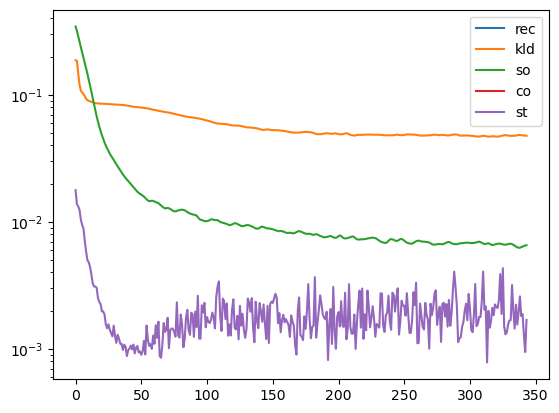

In [13]:
# plt.plot(np.array(losses[0])[:,:-1], label=['rec', 'kld', 'so', 'co', 'st'])
plt.plot(np.array(losses[1])[:,:-1], label=['rec', 'kld', 'so', 'co', 'st'])
plt.yscale('log')
plt.legend()

Text(0.5, 1.0, 'Space Z')

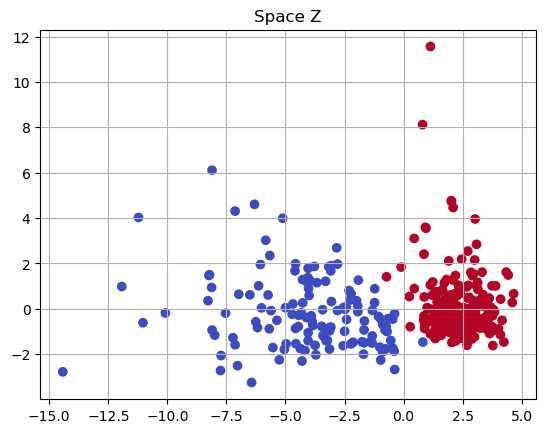

In [14]:
from sklearn.decomposition import PCA

Z = latent.Z_train.copy()
Y = latent.y_train[:, 1].copy()
Z = PCA().fit_transform(Z)

plt.scatter(Z[:,0], Z[:,1], c=Y, cmap='coolwarm')
plt.grid()
plt.title('Space Z')

Text(0.5, 1.0, 'Space W')

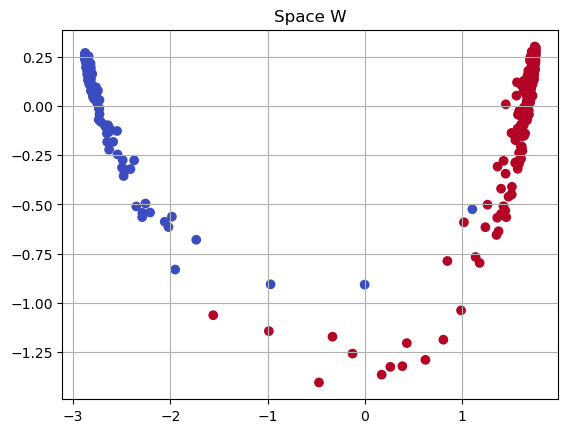

In [15]:
from sklearn.decomposition import PCA

W = latent.W_train.reshape(-1, np.prod(latent.W_train.shape[1:]))
Y = latent.y_train[:,1].copy()
Z = PCA().fit_transform(W)

plt.scatter(Z[:,0], Z[:,1], c=Y, cmap='coolwarm')
plt.grid()
plt.title('Space W')

# Local Explanations

### Feature importance

In [16]:
latent.explain_linear(num_k=2)

Training Logistic Regression surrogate.
LR surrogate score: 0.9912


In [17]:
fimp = latent.get_feature_importance(X_test, y_test_bb, num_k=2)

In [19]:
fimp = [[(att, ex[i]) for i,att in enumerate(feature_names) 
         if (ex[i]!=0.0) and (att in numeric_columns or x[i]==1.)] if np.all(ex!=None) else None 
         for ex,x in zip(fimp, X_test)]

In [20]:
fimp[0]

[('mean radius', np.float64(-0.4842992236351181)),
 ('mean compactness', np.float64(-1.0999723496033236)),
 ('mean concavity', np.float64(0.16480277277712113)),
 ('mean concave points', np.float64(-1.3483749878558753)),
 ('mean fractal dimension', np.float64(1.1295288279870488)),
 ('perimeter error', np.float64(-1.3532439254634305)),
 ('area error', np.float64(-0.3965928201748823)),
 ('smoothness error', np.float64(-0.5794935089066917)),
 ('compactness error', np.float64(-0.8858129668080373)),
 ('concavity error', np.float64(0.8360977480356676)),
 ('symmetry error', np.float64(0.14457900277315205)),
 ('fractal dimension error', np.float64(1.4352695391545174)),
 ('worst perimeter', np.float64(-0.8513484642841396)),
 ('worst area', np.float64(-0.8726194234915432)),
 ('worst smoothness', np.float64(-0.660419107009714)),
 ('worst compactness', np.float64(-1.088416143563159))]

### Decision Rules

In [21]:
latent.explain_dectree(num_k=2)

Training Decision Tree surrogate.
DT surrogate score: 0.9912


##### Factual rules

In [22]:
rules = latent.get_decision_rules(X_test, y_test_bb, num_k=2)

In [23]:
rules = [[(feature_names[int(att[1:])], op, val) 
          for (att, op), val in inverse_transform_rule_complete(ex, scaler, latent.idx_num).items()] if ex!=None else None  
          for ex in rules]

In [24]:
rules = [[(att, op, val) if att in numeric_columns 
          else (att.split('=')[0], ('=' if op=='>' else '!='), att.split('=')[1]) 
          for att, op, val in ex] if ex!=None else None  
          for ex in rules]

In [25]:
rules[0]

[('mean concave points', '>', np.float64(0.002854434526304135)),
 ('fractal dimension error', '<=', np.float64(0.00916739312834745)),
 ('worst perimeter', '>', np.float64(26.445578607222757)),
 ('worst area', '>', np.float64(652.2623339991246))]

##### Counterfactual rules/Counter-examples

In [26]:
crules, cfs = latent.get_counterfactuals(X_test, y_test_bb, num_k=2)

In [27]:
crules = [[[(feature_names[int(att[1:])], op , val) 
            for (att, op), val in inverse_transform_rule_complete(cx, scaler, latent.idx_num).items()] if cx!=None else None
            for cx in cx_list] for cx_list in crules]

In [28]:
crules = [[[(att, op, val) if att in numeric_columns 
          else (att.split('=')[0], ('=' if op=='>' else '!='), att.split('=')[1]) 
          for att, op, val in cx] if cx!=None else None 
          for cx in cx_list] for cx_list in crules]

In [29]:
crules[0]

[[('mean perimeter', '<=', np.float64(107.66718338411457)),
  ('mean area', '<=', np.float64(903.5946175458507)),
  ('radius error', '<=', np.float64(0.6475639636999359)),
  ('worst area', '<=', np.float64(1095.8003261621761)),
  ('worst concave points', '<=', np.float64(0.13174443140032066))]]

In [30]:
cfs = [np.concatenate((scaler.inverse_transform(cf[:, latent.idx_num]), (cf[:, latent.idx_cat] if latent.idx_cat!=None else cf[:, :0])), axis=1) if np.any(cf!=None) else cf for cf in cfs]